# Frequent Actor Groups in the IMDb Top 1000 Movies

**Algorithms for Massive Datasets** — Master in Data Science for Economics, Università degli Studi di Milano, A.Y. 2025/26

Each movie is a basket of its billed stars, and we look for groups of actors that often appear together. We use exhaustive counting as ground truth, A-Priori (basic and optimized) and PCY (RU ch. 6), and study how they scale with the data.

**Sections:** 0. Setup · 1. Data · 2. Algorithms · 3. Experiments on the original data · 4. Scalability · 5. Conclusions

## 0. Setup

On Colab, the cell below clones the repository and installs `requirements.txt`; locally, open the notebook from the repository root. All experiment parameters are set once, in the cell after it.

In [47]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/amd-market-basket-imdb").exists():
        !git clone --quiet --depth 1 --branch main https://github.com/TheRealMamoot/amd-market-basket-imdb.git /content/amd-market-basket-imdb
    %cd /content/amd-market-basket-imdb
    !pip install --quiet -r requirements.txt
    sys.path.insert(0, str(Path.cwd()))

In [ ]:
# Support threshold, as a number of movies, used to illustrate the algorithms in section 2
EXAMPLE_SUPPORT = 2
# Number of hash buckets used to illustrate PCY in section 2
EXAMPLE_BUCKETS = 100_000
# Support thresholds, as numbers of movies, for the experiments on the original data
SUPPORTS = [1, 2, 3, 5, 10]
# Timed runs per configuration; runtimes are summarised by their median
REPEATS = 3
# Numbers of hash buckets tried for PCY
BUCKETS = [1_000, 10_000, 100_000, 1_000_000]
# Dataset sizes for the scalability experiments, as numbers of copies of the original data
COPY_COUNTS = [1, 10, 50, 100]
# Base support thresholds, as numbers of original movies, for the scalability experiments
SCALING_SUPPORTS = [2, 5]
# Numbers of relabelled copies used for basic A-Priori, whose cost grows quadratically there
BASIC_COPY_COUNTS = [1, 2, 3, 4, 5]

## 1. Data

The [IMDB Movies Dataset](https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows) lists the 1000 top-rated titles on IMDb and is downloaded with the Kaggle API: on Colab, add a `KAGGLE_API_TOKEN` secret; locally, set it in `.env`. An existing download is reused.

In [49]:
import os

if IN_COLAB:
    from google.colab import userdata

    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [50]:
from src.data import download_dataset

dataset_path = download_dataset()
print(f"Dataset: {dataset_path}")

Dataset: /Users/mahmoudian/Projects/amd-market-basket-imdb/data/imdb_top_1000.csv


Only the billed stars (`Star1`–`Star4`) form the baskets; `Series_Title` is kept to read the results, and the whole dataset is used.

In [51]:
from src.preprocessing import ACTOR_COLUMNS, load_movies

movies = load_movies(dataset_path)
print(f"{movies.shape[0]} titles, {movies.shape[1]} columns")
movies[["Series_Title", *ACTOR_COLUMNS]].head()

1000 titles, 16 columns


,Series_Title,Star1,Star2,Star3,Star4
0,The Shawshank Redemption,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler
1,The Godfather,Marlon Brando,Al Pacino,James Caan,Diane Keaton
2,The Dark Knight,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine
3,The Godfather: Part II,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton
4,12 Angry Men,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler


A basket is a sorted tuple of distinct actor names, so every itemset has a single representation and the subsets generated by `itertools.combinations` can be looked up directly in the counts. `build_baskets` strips whitespace, drops empty names and merges repeated ones; `inspect_actors` reports how often each case occurs.

In [52]:
import inspect

from IPython.display import Code

from src.preprocessing import build_baskets


def show_source(*functions):
    return Code("\n\n".join(inspect.getsource(function) for function in functions), language="python")


show_source(build_baskets)

def build_baskets(movies: pd.DataFrame) -> list[tuple[str, ...]]:
    actors = _actor_columns(movies)
    baskets = []

    for row in actors.itertuples(index=False, name=None):
        basket = set()
        for value in row:
            name = _clean_actor(value)
            if name:
                basket.add(name)
        baskets.append(tuple(sorted(basket)))

    return baskets

In [53]:
from src.preprocessing import inspect_actors

quality = inspect_actors(movies)
quality

{'movies': 1000,
 'missing_names': {'Star1': 0, 'Star2': 0, 'Star3': 0, 'Star4': 0},
 'blank_names': {'Star1': 0, 'Star2': 0, 'Star3': 0, 'Star4': 0},
 'names_with_whitespace': {'Star1': 0, 'Star2': 0, 'Star3': 0, 'Star4': 0},
 'movies_with_repeated_actors': 4,
 'duplicate_actor_entries_removed': 4,
 'distinct_actors': 2709,
 'empty_baskets': 0,
 'basket_sizes': {3: 4, 4: 996}}

The only issue is four movies that list an actor twice, most likely an artefact of the source; after merging, their baskets have three actors.

In [54]:
from src.preprocessing import ACTOR_COLUMNS

stars = movies[list(ACTOR_COLUMNS)]
movies.loc[stars.nunique(axis=1) < len(ACTOR_COLUMNS), ["Series_Title", *ACTOR_COLUMNS]]

,Series_Title,Star1,Star2,Star3,Star4
120,Singin' in the Rain,Gene Kelly,Gene Kelly,Donald O'Connor,Debbie Reynolds
320,The General,Buster Keaton,Buster Keaton,Marion Mack,Glen Cavender
727,What We Do in the Shadows,Taika Waititi,Jemaine Clement,Taika Waititi,Cori Gonzalez-Macuer
815,Il postino,Massimo Troisi,Massimo Troisi,Philippe Noiret,Maria Grazia Cucinotta


In [55]:
from collections import Counter

from src.preprocessing import build_baskets

baskets = build_baskets(movies)
actor_counts = Counter(actor for basket in baskets for actor in basket)

print(f"Baskets: {len(baskets)}, sizes {dict(sorted(Counter(map(len, baskets)).items()))}")
print(f"Distinct actors: {len(actor_counts)}, distinct baskets: {len(set(baskets))}")
for title, basket in zip(movies["Series_Title"].head(3), baskets):
    print(f"{title}: {basket}")

Baskets: 1000, sizes {3: 4, 4: 996}
Distinct actors: 2709, distinct baskets: 996
The Shawshank Redemption: ('Bob Gunton', 'Morgan Freeman', 'Tim Robbins', 'William Sadler')
The Godfather: ('Al Pacino', 'Diane Keaton', 'James Caan', 'Marlon Brando')
The Dark Knight: ('Aaron Eckhart', 'Christian Bale', 'Heath Ledger', 'Michael Caine')


The four repeated baskets are sequel pairs with identical casts. They stay separate, because support counts movies.

In [56]:
titles_by_basket = {}
for title, basket in zip(movies["Series_Title"], baskets):
    titles_by_basket.setdefault(basket, []).append(title)

for basket, titles in titles_by_basket.items():
    if len(titles) > 1:
        print(f"{basket}\n    {titles}")

('Elijah Wood', 'Ian McKellen', 'Orlando Bloom', 'Viggo Mortensen')
    ['The Lord of the Rings: The Return of the King', 'The Lord of the Rings: The Two Towers']
('Billy Dee Williams', 'Carrie Fisher', 'Harrison Ford', 'Mark Hamill')
    ['Star Wars: Episode V - The Empire Strikes Back', 'Star Wars: Episode VI - Return of the Jedi']
('Daniel Radcliffe', 'Emma Watson', 'Michael Gambon', 'Rupert Grint')
    ['Harry Potter and the Deathly Hallows: Part 2', 'Harry Potter and the Half-Blood Prince']
('Daryl Hannah', 'David Carradine', 'Michael Madsen', 'Uma Thurman')
    ['Kill Bill: Vol. 1', 'Kill Bill: Vol. 2']


Appearances have a long tail: 2,068 of the 2,709 actors appear in a single movie, so lowering the support threshold $s$ from 5 to 2 raises the number of frequent actors from 79 to 641.

In [57]:
import pandas as pd

actor_series = pd.Series(actor_counts)
display(actor_series.value_counts().sort_index().rename_axis("movies").rename("actors").to_frame().T)
display(actor_series.sort_values(ascending=False).head(10).rename_axis("actor").rename("movies").to_frame())

movies,1,2,3,4,5,6,7,8,9,10,11,12,13,14,17
actors,2068,370,126,66,20,29,13,2,6,1,3,2,1,1,1


,movies
actor,
Robert De Niro,17
Tom Hanks,14
Al Pacino,13
Clint Eastwood,12
Brad Pitt,12
Leonardo DiCaprio,11
Christian Bale,11
Matt Damon,11
James Stewart,10


## 2. Algorithms

The support of an itemset is the number of baskets that contain it, and the itemset is frequent if its support is at least $s$. $L_k$ denotes the frequent itemsets of size $k$, $C_k$ the candidates counted for size $k$, and $m$ the number of frequent actors. Each algorithm returns every frequent itemset with its support; here each one runs on its own at $s$ = `EXAMPLE_SUPPORT` and is checked against exhaustive counting, and section 3 compares them.

**Exhaustive counting** counts every non-empty subset of every basket in a single pass. A basket of $b$ actors has $2^b - 1$ of them, at most 15 here, so it is cheap on this dataset and serves as ground truth, but it does not scale to larger baskets.

In [58]:
from src.exhaustive import count_exhaustive

show_source(count_exhaustive)

def count_exhaustive(
    baskets: list[tuple[str, ...]], min_support: int
) -> dict[tuple[str, ...], int]:
    if min_support < 1:
        raise ValueError("Minimum support must be at least 1.")

    counts = Counter()

    for basket in baskets:
        for size in range(1, len(basket) + 1):
            for group in combinations(basket, size):
                counts[group] += 1

    frequent_itemsets = {}
    for group, count in counts.items():
        if count >= min_support:
            frequent_itemsets[group] = count

    return frequent_itemsets

In [59]:
import time

from src.exhaustive import count_exhaustive

truth = count_exhaustive(baskets, EXAMPLE_SUPPORT)
print(f"Frequent itemsets by size: {dict(sorted(Counter(map(len, truth)).items()))}")
groups = {", ".join(itemset): count for itemset, count in truth.items() if len(itemset) > 1}
pd.Series(groups).sort_values(ascending=False).head(10).rename_axis("actors").rename("movies").to_frame()

Frequent itemsets by size: {1: 641, 2: 121, 3: 25, 4: 4}


,movies
actors,
"Daniel Radcliffe, Rupert Grint",6
"Emma Watson, Rupert Grint",5
"Daniel Radcliffe, Emma Watson, Rupert Grint",5
"Daniel Radcliffe, Emma Watson",5
"Joe Pesci, Robert De Niro",4
"Tim Allen, Tom Hanks",4
"Diane Keaton, Woody Allen",3
"Mark Ruffalo, Robert Downey Jr.",3
"Carrie Fisher, Harrison Ford, Mark Hamill",3


**A-Priori** (RU §6.2) relies on monotonicity: every subset of a frequent itemset is frequent. Pass $k$ therefore only counts the candidates $C_k$, the itemsets of size $k$ whose subsets of size $k - 1$ are all in $L_{k-1}$, and keeps those with support at least $s$ as $L_k$. The basic version builds $C_k$ by joining itemsets of $L_{k-1}$ that share their first $k - 2$ actors and pruning those with an infrequent subset (`generate_candidates`), then counts them by enumerating the $k$-subsets of every basket (`count_candidates`, below).

In [60]:
from src.apriori import count_candidates

show_source(count_candidates)

def count_candidates(baskets, candidates, min_support, actors=None):
    counts = Counter()

    if not candidates:
        return {}

    size = len(next(iter(candidates)))

    for basket in baskets:
        if actors is not None:
            basket = trim_basket(basket, actors)
        for group in combinations(basket, size):
            if group in candidates:
                counts[group] += 1

    frequent = {}
    for candidate, count in counts.items():
        if count >= min_support:
            frequent[candidate] = count

    return frequent

In [61]:
from src.apriori import apriori

stats = {}
result = apriori(baskets, EXAMPLE_SUPPORT, stats=stats)
print(f"Same result as exhaustive counting: {result == truth}")
print(f"Candidates stored per itemset size: {stats['counters']}")

Same result as exhaustive counting: True
Candidates stored per itemset size: {2: 205120, 3: 26, 4: 4}


Timing the two steps of each pass separately shows the bottleneck: at low support almost all the time goes into building candidates, not counting them. Since every pair of frequent actors is a candidate, $C_2$ holds $m(m-1)/2$ pairs: 3,667,986 for $m$ = 2,709 at $s$ = 1, and 205,120 for $m$ = 641 at $s$ = 2, where only 121 pairs are frequent.

In [62]:
from src.apriori import count_candidates, find_frequent_singles, generate_candidates

rows = []
for support in (min(SUPPORTS), EXAMPLE_SUPPORT):
    frequent = find_frequent_singles(baskets, support)
    size = 2
    while frequent:
        start = time.perf_counter()
        candidates = generate_candidates(frequent, size)
        generation = time.perf_counter() - start
        if not candidates:
            break
        start = time.perf_counter()
        frequent = count_candidates(baskets, candidates, support)
        counting = time.perf_counter() - start
        rows.append(
            {
                "support": support,
                "size": size,
                "candidates": len(candidates),
                "frequent": len(frequent),
                "generation_s": generation,
                "counting_s": counting,
            }
        )
        size += 1

pd.DataFrame(rows).round(4)

,support,size,candidates,frequent,generation_s,counting_s
0,1,2,3667986,5833,3.4979,0.0346
1,1,3,4007,3958,2.2538,0.0023
2,1,4,992,992,0.8683,0.0008
3,2,2,205120,121,0.1737,0.0021
4,2,3,26,25,0.0123,0.0003
5,2,4,4,4,0.0001,0.0002


The cause is visible in `generate_candidates`: it compares every pair of itemsets in $L_{k-1}$ and discards those whose first $k - 2$ actors differ; for $k$ = 2 the prefix is empty, so every pair of frequent actors becomes a candidate. The optimized version below counts pairs directly instead, and for $k \ge 3$ uses `generate_candidates_by_prefix`, which first groups $L_{k-1}$ by prefix and joins only within each group.

In [63]:
from src.apriori import generate_candidates_by_prefix

show_source(generate_candidates, generate_candidates_by_prefix)

def generate_candidates(frequent, size):
    previous_groups = sorted(frequent)
    previous_set = set(previous_groups)
    candidates = set()

    for left, right in combinations(previous_groups, 2):
        if left[: size - 2] != right[: size - 2]:
            continue

        candidate = tuple(sorted(set(left) | set(right)))
        if len(candidate) != size:
            continue

        keep = True
        for subset in combinations(candidate, size - 1):
            if subset not in previous_set:
                keep = False
                break

        if keep:
            candidates.add(candidate)

    return candidates


def generate_candidates_by_prefix(frequent, size):
    previous_set = set(frequent)
    groups_by_prefix = {}
    for group in sorted(frequent):
        groups_by_prefix.setdefault(group[:-1], []).append(group)

    candidates = set()
    for members in groups_by_prefix.values():
        for left, right in combinations(members, 2):
            candidate = left + (right[-1],)

            keep = True
            for subset in combinations(candidate, size - 1):
                if subset not in previous_set:
                    keep = False
                    break

            if keep:
                candidates.add(candidate)

    return candidates

**Optimized A-Priori** removes this bottleneck without changing the result:

- pairs are counted directly from the frequent actors of each basket, so only pairs that actually occur get a counter (the "triples" method, RU §6.2.2): 1,516 counters at $s$ = 2, where basic A-Priori stores 205,120 candidate pairs;
- for $k \ge 3$ the join only combines itemsets with the same first $k - 2$ actors (`generate_candidates_by_prefix`);
- before its subsets are enumerated, each basket is trimmed to the actors that appear in $L_{k-1}$.

In [64]:
from src.apriori import apriori, count_frequent_pairs, trim_basket

show_source(trim_basket, count_frequent_pairs, apriori)

def trim_basket(basket, actors):
    kept = []
    for actor in basket:
        if actor in actors:
            kept.append(actor)
    return kept


def count_frequent_pairs(baskets, actors, min_support):
    counts = Counter()

    for basket in baskets:
        for pair in combinations(trim_basket(basket, actors), 2):
            counts[pair] += 1

    frequent = {}
    for pair, count in counts.items():
        if count >= min_support:
            frequent[pair] = count

    return frequent, len(counts)


def apriori(
    baskets: list[tuple[str, ...]],
    min_support: int,
    optimized: bool = False,
    stats: dict | None = None,
) -> dict[tuple[str, ...], int]:
    if min_support < 1:
        raise ValueError("Minimum support must be at least 1.")

    frequent = find_frequent_singles(baskets, min_support)
    results = frequent.copy()
    size = 2

    largest_basket = 0
    for basket in baskets:
        largest_basket = max(largest_basket, len(basket))

    while frequent and size <= largest_basket:
        if optimized:
            actors = frequent_actors(frequent)
            if size == 2:
                frequent, counted = count_frequent_pairs(baskets, actors, min_support)
                record_counters(stats, size, counted)
            else:
                candidates = generate_candidates_by_prefix(frequent, size)
                if not candidates:
                    break
                record_counters(stats, size, len(candidates))
                frequent = count_candidates(baskets, candidates, min_support, actors)
        else:
            candidates = generate_candidates(frequent, size)
            if not candidates:
                break
            record_counters(stats, size, len(candidates))
            frequent = count_candidates(baskets, candidates, min_support)

        results.update(frequent)
        size += 1

    return results

In [65]:
stats = {}
result = apriori(baskets, EXAMPLE_SUPPORT, optimized=True, stats=stats)
larger = {size: count for size, count in stats["counters"].items() if size > 2}
print(f"Same result as exhaustive counting: {result == truth}")
print(f"Pair counters: {stats['counters'][2]:,}; candidates for larger itemsets: {larger}")

Same result as exhaustive counting: True
Pair counters: 1,516; candidates for larger itemsets: {3: 26, 4: 4}


**PCY** (RU §6.3.1) uses the memory left idle in pass 1: while counting actors, it hashes every pair of each basket into one of $B$ buckets and counts how many pairs fall into each bucket. Pass 2 counts a pair only if both actors are frequent and its bucket count is at least $s$. A bucket's count is at least the support of any pair hashed to it, so no frequent pair is lost; later passes are those of optimized A-Priori. The average bucket count, the number of pair occurrences $P$ divided by $B$, is a rough guide (RU Example 6.9): as it approaches $s$, more and more buckets become frequent and less is filtered; here $P$ = 5,988.

The hashing and the filter, from `src/pcy.py`: actors receive integer ids in order of appearance, and a pair is hashed from the ids of its two actors.

In [66]:
from src.pcy import bucket_of, count_pcy_pairs, first_pass

show_source(bucket_of, first_pass, count_pcy_pairs)

def bucket_of(left_id, right_id, num_buckets):
    return (left_id * HASH_MULTIPLIER + right_id) % num_buckets


def first_pass(baskets, num_buckets):
    actor_counts = Counter()
    actor_ids = {}
    bucket_counts = [0] * num_buckets

    for basket in baskets:
        ids = []
        for actor in basket:
            actor_counts[actor] += 1
            if actor not in actor_ids:
                actor_ids[actor] = len(actor_ids)
            ids.append(actor_ids[actor])

        for left_id, right_id in combinations(ids, 2):
            bucket_counts[bucket_of(left_id, right_id, num_buckets)] += 1

    return actor_counts, actor_ids, bucket_counts


def count_pcy_pairs(baskets, actors, actor_ids, bitmap, min_support):
    counts = Counter()
    num_buckets = len(bitmap)

    for basket in baskets:
        for left, right in combinations(trim_basket(basket, actors), 2):
            bucket = bucket_of(actor_ids[left], actor_ids[right], num_buckets)
            if bitmap[bucket]:
                counts[(left, right)] += 1

    frequent = {}
    for pair, count in counts.items():
        if count >= min_support:
            frequent[pair] = count

    return frequent, len(counts)

In [67]:
from src.pcy import pcy

stats = {}
result = pcy(baskets, EXAMPLE_SUPPORT, EXAMPLE_BUCKETS, stats=stats)
larger = {size: count for size, count in stats["counters"].items() if size > 2}
print(f"Same result as exhaustive counting: {result == truth}")
print(f"Frequent buckets: {stats['frequent_buckets']:,} of {stats['buckets']:,}")
print(f"Pair counters: {stats['counters'][2]:,}; candidates for larger itemsets: {larger}")

Same result as exhaustive counting: True
Frequent buckets: 238 of 100,000
Pair counters: 192; candidates for larger itemsets: {3: 26, 4: 4}


## 3. Experiments on the original data

Every algorithm runs at each $s$ in `SUPPORTS`, and PCY once per $B$ in `BUCKETS`. Each configuration first runs once untimed as a warm-up, then `REPEATS` times with the order of the algorithms reversed between repeats. Garbage is collected before each run and the collector is disabled during it, as Python's `timeit` does, so that no collection triggered by one algorithm's objects is charged to another. Times are summarised by their median, and `run_experiments` stops if any result differs from exhaustive counting.

The pairs stored for pass 2 are the candidate pairs for basic A-Priori, which builds $C_2$ before counting, and the counters of pairs that actually occur for optimized A-Priori and PCY.

In [68]:
from src.experiments import run_experiments

names = {"exhaustive": "Exhaustive", "apriori": "A-Priori (basic)", "apriori_optimized": "A-Priori (optimized)"}
methods = list(names.values()) + [f"PCY ({num_buckets:,} buckets)" for num_buckets in BUCKETS]


def label_runs(rows):
    frame = pd.DataFrame(rows)
    frame["method"] = [
        f"PCY ({num_buckets:,} buckets)" if algorithm == "pcy" else names[algorithm]
        for algorithm, num_buckets in zip(frame["algorithm"], frame["buckets"])
    ]
    frame["pair_counters"] = pd.to_numeric(frame["pair_counters"], errors="coerce")
    return frame


def pair_label(method):
    return f"{method}: candidate pairs" if method == "A-Priori (basic)" else f"{method}: pair counters"


measurements = label_runs(run_experiments(baskets, SUPPORTS, REPEATS, buckets=BUCKETS, verbose=False))

summary = measurements.groupby(["min_support", "method"]).agg(
    median_s=("runtime_seconds", "median"),
    pairs_stored=("pair_counters", "first"),
)
print(f"All {len(measurements)} runs match exhaustive counting.")
display(summary["median_s"].unstack()[methods].round(4))
display(summary["pairs_stored"].unstack()[methods[1:]].astype(int).rename(columns=pair_label))

All 105 runs match exhaustive counting.


method,Exhaustive,A-Priori (basic),A-Priori (optimized),"PCY (1,000 buckets)","PCY (10,000 buckets)","PCY (100,000 buckets)","PCY (1,000,000 buckets)"
min_support,,,,,,,
1,0.0049,6.3070,0.0171,0.0193,0.0212,0.0260,0.0582
2,0.0044,0.1490,0.0024,0.0038,0.0039,0.0068,0.0325
3,0.0041,0.0260,0.0017,0.0033,0.0030,0.0058,0.0349
5,0.0043,0.0037,0.0016,0.0027,0.0030,0.0057,0.0311
10,0.0080,0.0013,0.0012,0.0022,0.0026,0.0060,0.0318


method,A-Priori (basic): candidate pairs,A-Priori (optimized): pair counters,"PCY (1,000 buckets): pair counters","PCY (10,000 buckets): pair counters","PCY (100,000 buckets): pair counters","PCY (1,000,000 buckets): pair counters"
min_support,,,,,,
1,3667986,5833,5833,5833,5833,5833
2,205120,1516,1508,696,192,129
3,36585,622,612,82,27,25
5,3081,139,120,5,3,3
10,36,9,1,0,0,0


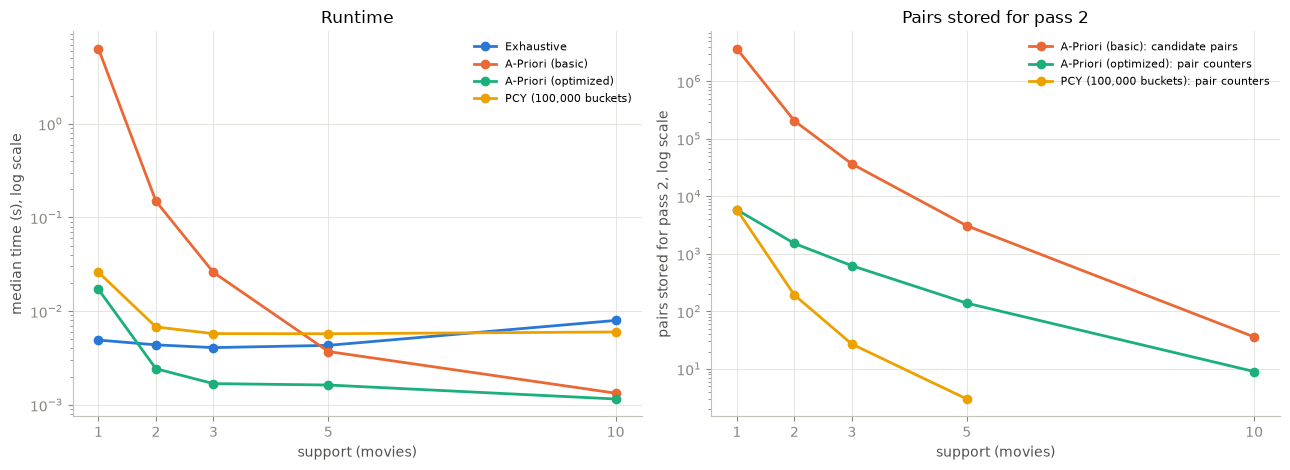

In [69]:
import matplotlib.pyplot as plt

plotted = {
    "Exhaustive": "#2a78d6",
    "A-Priori (basic)": "#eb6834",
    "A-Priori (optimized)": "#1baf7a",
    f"PCY ({EXAMPLE_BUCKETS:,} buckets)": "#eda100",
}

plt.rcParams.update(
    {
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
    }
)
fig, (runtime_ax, pairs_ax) = plt.subplots(1, 2, figsize=(13, 4.8))
for method, color in plotted.items():
    rows = summary.xs(method, level="method")
    runtime_ax.plot(rows.index, rows["median_s"], color=color, linewidth=2, marker="o", markersize=6, label=method)
    if method != "Exhaustive":
        stored = rows["pairs_stored"].where(rows["pairs_stored"] > 0)
        pairs_ax.plot(rows.index, stored, color=color, linewidth=2, marker="o", markersize=6, label=pair_label(method))

runtime_ax.set(xlabel="support (movies)", ylabel="median time (s), log scale", yscale="log", title="Runtime", xticks=SUPPORTS)
pairs_ax.set(xlabel="support (movies)", ylabel="pairs stored for pass 2, log scale", yscale="log", title="Pairs stored for pass 2", xticks=SUPPORTS)
for ax in (runtime_ax, pairs_ax):
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

Exhaustive counting takes about the same time at every $s$, because it always counts all subsets. Basic A-Priori follows its candidate pairs, which fall from 3,667,986 at $s$ = 1 to 36 at $s$ = 10: its time falls from seconds to about a millisecond. Optimized A-Priori stores 5,833 pair counters at $s$ = 1 and 1,516 at $s$ = 2, and is the fastest method from $s$ = 2 upwards, level with basic at $s$ = 10, where there is almost nothing to prune; at $s$ = 1, where every subset is frequent and nothing can be pruned, exhaustive counting is faster.

PCY needs the fewest pair counters, down to 129 at $s$ = 2 with a million buckets against 121 frequent pairs (none at $s$ = 10, so that point is missing from the log scale), but it is consistently slower than optimized A-Priori: pass 1 hashes every pair, and the bucket array adds a cost that grows with $B$. RU presents PCY as a way to reduce the memory of the second pass. Here it reduces the number of pair counters, but not total memory: this implementation keeps the bucket counts allocated during pass 2 and stores the bitmap with one byte per bucket.

## 4. Scalability

Every counting pass of A-Priori and PCY reads each basket once, and there is at most one more pass than the size of the largest frequent itemset (five passes here), so the cost of reading grows linearly with the number of baskets $n$. The total time also includes building candidates, which depends on the frequent itemsets rather than on $n$ and can grow faster when they grow; the memory of the counters likewise depends on $m$, on the distinct pairs and on $B$, not on $n$, while the baskets themselves are held in memory here and grow with $n$.

To test this beyond 1000 movies, the data is enlarged to $r$ copies, $r$ in `COPY_COUNTS`, in two ways:

- **Plain stacking** repeats the baskets. Every support is multiplied by $r$, and so is the threshold (a constant fraction of the baskets), so the frequent itemsets stay the same: only the number of baskets changes.
- **Relabelled stacking** renames the actors in each copy (`Tom Hanks#2`, …), so the distinct actors and pairs grow $r$-fold while each renamed itemset keeps its original support. The threshold stays the fixed count $s$, and the result is $r$ renamed copies of the original one; with a constant fraction, nothing would remain frequent once $r$ exceeds the largest support divided by $s$.

In both cases the exact result is known in advance, and `run_scaling_experiments` checks it as well as the agreement with exhaustive counting. Both are controlled workloads: they isolate the effect of more baskets and of more distinct actors, but they do not reproduce how real data would grow, and they create no new co-occurrences, so the findings about actors come from the original data only.

In [70]:
from src.stacking import augmented_support, relabel_baskets, relabel_group

show_source(relabel_group, relabel_baskets, augmented_support)

def relabel_group(group: tuple[str, ...], copy: int) -> tuple[str, ...]:
    renamed = []
    for actor in group:
        renamed.append(relabel_actor(actor, copy))
    return tuple(sorted(renamed))


def relabel_baskets(
    baskets: list[tuple[str, ...]], copies: int
) -> list[tuple[str, ...]]:
    _check_copies(copies)
    relabeled = []
    for copy in range(1, copies + 1):
        for basket in baskets:
            relabeled.append(relabel_group(basket, copy))
    return relabeled


def augmented_support(base_support: int, copies: int, augmentation: str = "plain") -> int:
    _check_copies(copies)
    _check_augmentation(augmentation)
    if augmentation == "plain":
        return base_support * copies
    return base_support

In [71]:
from src.experiments import run_scaling_experiments

plain = label_runs(
    run_scaling_experiments(
        baskets, COPY_COUNTS, SCALING_SUPPORTS, REPEATS, "plain", list(names)[1:] + ["pcy"], BUCKETS, verbose=False
    )
)
print(f"Plain stacking: all {len(plain)} runs match exhaustive counting and the expected result.")
plain.groupby(["base_support", "movies", "method"])["runtime_seconds"].median().unstack()[methods].round(4)

Plain stacking: all 168 runs match exhaustive counting and the expected result.


method               Exhaustive  A-Priori (basic)  A-Priori (optimized)  \
base_support movies                                                       
2            1000        0.0047            0.1574                0.0025   
             10000       0.0279            0.1713                0.0202   
             50000       0.1282            0.2329                0.0858   
             100000      0.2507            0.3331                0.1653   
5            1000        0.0042            0.0038                0.0019   
             10000       0.0292            0.0157                0.0121   
             50000       0.1526            0.0668                0.0659   
             100000      0.2474            0.1254                0.1122   

method               PCY (1,000 buckets)  PCY (10,000 buckets)  \
base_support movies                                              
2            1000                 0.0041                0.0039   
             10000                0.0302                0.0288   
             50000                0.1612                0.1402   
             100000               0.3085                0.2829   
5            1000                 0.0026                0.0029   
             10000                0.0220                0.0227   
             50000                0.1166                0.1066   
             100000               0.2234                0.2178   

method               PCY (100,000 buckets)  PCY (1,000,000 buckets)  
base_support movies                                                  
2            1000                   0.0069                   0.0342  
             10000                  0.0304                   0.0568  
             50000                  0.1415                   0.1800  
             100000                 0.2832                   0.3069  
5            1000                   0.0054                   0.0312  
             10000                  0.0248                   0.0534  
             50000                  0.1397                   0.1469  
             100000                 0.2190                   0.2411

In [72]:
relabeled = label_runs(
    run_scaling_experiments(
        baskets, COPY_COUNTS, SCALING_SUPPORTS, REPEATS, "relabeled", ["apriori_optimized", "pcy"], BUCKETS, verbose=False
    )
)
relabeled_methods = [method for method in methods if method != "A-Priori (basic)"]
print(f"Relabelled stacking: all {len(relabeled)} runs match exhaustive counting and the expected result.")
display(relabeled.groupby(["base_support", "movies", "method"])["runtime_seconds"].median().unstack()[relabeled_methods].round(4))
display(
    relabeled.groupby(["base_support", "movies", "method"])["pair_counters"]
    .first()
    .unstack()[relabeled_methods[1:]]
    .astype(int)
    .rename(columns=pair_label)
)

Relabelled stacking: all 144 runs match exhaustive counting and the expected result.


method               Exhaustive  A-Priori (optimized)  PCY (1,000 buckets)  \
base_support movies                                                          
2            1000        0.0045                0.0025               0.0039   
             10000       0.0446                0.0251               0.0410   
             50000       0.2602                0.1333               0.2092   
             100000      0.5625                0.2741               0.4563   
5            1000        0.0043                0.0015               0.0027   
             10000       0.0446                0.0167               0.0282   
             50000       0.2280                0.0768               0.1384   
             100000      0.6945                0.1832               0.3328   

method               PCY (10,000 buckets)  PCY (100,000 buckets)  \
base_support movies                                                
2            1000                  0.0040                 0.0065   
             10000                 0.0433                 0.0421   
             50000                 0.2273                 0.2243   
             100000                0.4509                 0.4456   
5            1000                  0.0031                 0.0058   
             10000                 0.0288                 0.0308   
             50000                 0.1346                 0.1376   
             100000                0.3368                 0.2901   

method               PCY (1,000,000 buckets)  
base_support movies                           
2            1000                     0.0347  
             10000                    0.0721  
             50000                    0.2639  
             100000                   0.4860  
5            1000                     0.0330  
             10000                    0.0571  
             50000                    0.1759  
             100000                   0.3569

method               A-Priori (optimized): pair counters  \
base_support movies                                        
2            1000                                   1516   
             10000                                 15160   
             50000                                 75800   
             100000                               151600   
5            1000                                    139   
             10000                                  1390   
             50000                                  6950   
             100000                                13900   

method               PCY (1,000 buckets): pair counters  \
base_support movies                                       
2            1000                                  1508   
             10000                                15160   
             50000                                75800   
             100000                              151600   
5            1000                                   120   
             10000                                 1390   
             50000                                 6950   
             100000                               13900   

method               PCY (10,000 buckets): pair counters  \
base_support movies                                        
2            1000                                    696   
             10000                                 15122   
             50000                                 75800   
             100000                               151600   
5            1000                                      5   
             10000                                  1184   
             50000                                  6950   
             100000                                13900   

method               PCY (100,000 buckets): pair counters  \
base_support movies                                         
2            1000                                     192   
             10000                                   7325   
             50000                                  72549   
             100000                                151432   
5            1000                                       3   
             10000                                     50   
             50000                                   2789   
             100000                                 11932   

method               PCY (1,000,000 buckets): pair counters  
base_support movies                                          
2            1000                                       129  
             10000                                     1941  
             50000                                    22263  
             100000                                   72676  
5            1000                                         3  
             10000                                       30  
             50000                                      150  
             100000                                     413

Basic A-Priori runs only for $r$ in `BASIC_COPY_COUNTS`, once per size after a warm-up: its candidate pairs grow with the square of $r$, and beyond $r$ = 5 they take gigabytes of memory, which makes its times depend on the memory available on the machine.

In [73]:
basic_relabeled = label_runs(
    run_scaling_experiments(baskets, BASIC_COPY_COUNTS, [EXAMPLE_SUPPORT], 1, "relabeled", ["apriori"], verbose=False)
)
basic_relabeled.pivot_table(index="movies", columns="method", values="runtime_seconds").round(4)

method,A-Priori (basic),Exhaustive
movies,,
1000,0.1432,0.0042
2000,0.6108,0.0092
3000,1.4396,0.0133
4000,2.7466,0.0202
5000,4.2955,0.0228


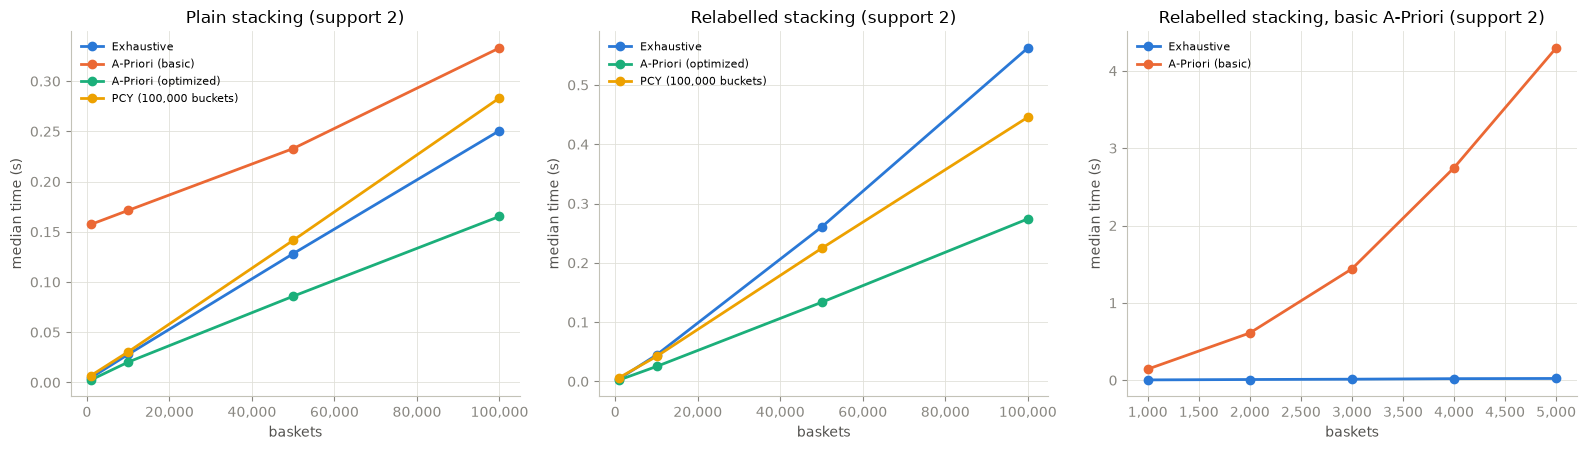

In [74]:
from matplotlib.ticker import StrMethodFormatter

fig, (plain_ax, relabeled_ax, basic_ax) = plt.subplots(1, 3, figsize=(16, 4.6))
panels = (
    (plain_ax, plain, "Plain stacking"),
    (relabeled_ax, relabeled, "Relabelled stacking"),
    (basic_ax, basic_relabeled, "Relabelled stacking, basic A-Priori"),
)
for ax, frame, title in panels:
    runs = frame[frame["base_support"] == EXAMPLE_SUPPORT]
    medians = runs.groupby(["method", "movies"])["runtime_seconds"].median()
    for method, color in plotted.items():
        if method in medians.index.get_level_values("method"):
            ax.plot(medians[method].index, medians[method].values, color=color, linewidth=2, marker="o", markersize=6, label=method)
    ax.set(title=f"{title} (support {EXAMPLE_SUPPORT})", xlabel="baskets", ylabel="median time (s)")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

Individual times vary between runs and machines, so growth is summarised by an exponent: the slope of log time against log baskets, fitted on the sizes from 10,000 baskets upwards (from 2,000 for basic A-Priori), where timings are most stable. An exponent close to 1 means linear growth, close to 2 quadratic.

In [75]:
import numpy as np

fits = (
    ("plain", plain, 10_000),
    ("relabelled", relabeled, 10_000),
    ("relabelled", basic_relabeled[basic_relabeled["method"] == "A-Priori (basic)"], 2_000),
)
rows = []
for augmentation, frame, smallest in fits:
    for (support, method), runs in frame.groupby(["base_support", "method"]):
        medians = runs.groupby("movies")["runtime_seconds"].median()
        medians = medians[medians.index >= smallest]
        slope = np.polyfit(np.log(medians.index.to_numpy(float)), np.log(medians.to_numpy()), 1)[0]
        rows.append({"method": method, "augmentation": augmentation, "support": support, "exponent": slope})

pd.DataFrame(rows).pivot_table(index="method", columns=["augmentation", "support"], values="exponent").reindex(methods).round(2)

augmentation            plain       relabelled      
support                     2     5          2     5
method                                              
Exhaustive               0.95  0.95       1.10  1.16
A-Priori (basic)         0.27  0.90       2.14   NaN
A-Priori (optimized)     0.91  0.98       1.04  1.02
PCY (1,000 buckets)      1.02  1.01       1.04  1.06
PCY (10,000 buckets)     0.99  0.98       1.02  1.05
PCY (100,000 buckets)    0.97  0.97       1.03  0.97
PCY (1,000,000 buckets)  0.73  0.65       0.82  0.78

Under plain stacking the frequent itemsets do not change, and exhaustive counting, optimized A-Priori and PCY grow approximately linearly with the number of baskets. Two exceptions grow more slowly, because a fixed cost is still a large part of their time at these sizes: basic A-Priori at $s$ = 2, where building its 205,120 candidate pairs costs the same at every size, and PCY with a million buckets, where setting up the buckets does. Optimized A-Priori is the fastest at every size.

Under relabelled stacking $m$ grows with $r$. Optimized A-Priori and PCY still grow approximately linearly (PCY with a million buckets again more slowly), because they only count pairs that occur, while exhaustive counting is slower than under plain stacking because its table of distinct subsets grows. Basic A-Priori grows roughly quadratically, with an exponent slightly above 2, since its candidate pairs grow with the square of $m$; at $r$ = 100 it would need about two billion of them, the "tyranny of counting pairs" of RU §6.2.4.

The pair counters show the limit of PCY: the average bucket count grows with $r$, so $B$ must grow too. With 100,000 buckets PCY filters well on the original data but almost nothing at $r$ = 100 (151,432 of 151,600 pairs are still counted, with an average bucket count of about 6, above $s$). With a million buckets the average is about 0.6, and it still removes about half of the pairs at $s$ = 2 and 97% at $s$ = 5.

## 5. Conclusions

**Findings.** At $s$ = 2 there are 641 frequent actors, 121 frequent pairs, 25 triples and 4 groups of four. The strongest groups are franchise casts, such as Daniel Radcliffe and Rupert Grint in six *Harry Potter* films and Tom Hanks and Tim Allen in the four *Toy Story* films, and long-running collaborations, such as Robert De Niro and Joe Pesci in four Scorsese films. Since most actors appear in a single movie, frequent groups are few and small.

**Methods.** All methods return identical results, checked against exhaustive counting on every run and against the known result on the enlarged data. With at most four actors per basket, exhaustive counting is hard to beat on the original data. Basic A-Priori is dominated by building every pair of frequent actors as a candidate; optimized A-Priori avoids this and is the fastest method wherever pruning is possible. PCY needs the fewest pair counters in the second pass (129 instead of 1,516 at $s$ = 2 with a million buckets), but it is consistently slower, and in this implementation it does not reduce total memory, because the bucket counts stay allocated.

**Scalability.** Under both enlargements, optimized A-Priori and PCY grow approximately linearly with the number of baskets. Basic A-Priori grows roughly quadratically when the actors grow, and PCY keeps filtering well only if $B$ grows with the pair occurrences, so that the average bucket count stays well below $s$.

**Limitations.** Baskets have at most four actors, which keeps exhaustive counting feasible and the frequent itemsets small. The enlarged datasets are controlled workloads that repeat existing co-occurrences: they show how the costs respond to more baskets and more distinct actors, not how real data would grow. Everything runs in memory on one machine, so a pass is a loop over a list rather than a read from disk, and memory is described by the number of counters rather than measured. Times vary between runs and machines; the counts are exact and reproduce on every run.

**Extensions.** Since much of the remaining cost is reading all the baskets once per pass, the limited-pass algorithms of RU §6.4 are the natural next step: Toivonen's algorithm mines a sample in memory and then verifies it with one full pass, repeated with a new sample if the verification fails, and SON distributes the passes over a cluster with MapReduce or Spark.